<a href="https://colab.research.google.com/github/JonathanDP02/244107020197-Pembelajaran-Mesin/blob/main/JS09_Tugas_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [2]:
df = pd.read_csv('/content/voice.csv')

print('--- Informasi 5 Data Teratas ---')
print(df.head())

le = LabelEncoder()
df['label'] = le.fit_transform(df['label'])

X = df.drop('label', axis=1)
y = df['label']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

knn_base = KNeighborsClassifier(n_neighbors=5)
knn_base.fit(X_train, y_train)
y_pred_base = knn_base.predict(X_test)
print(f'\nAkurasi Model kNN Dasar (k=5): {accuracy_score(y_test, y_pred_base):.4f}')

--- Informasi 5 Data Teratas ---
   meanfreq        sd    median       Q25       Q75       IQR       skew  \
0  0.059781  0.064241  0.032027  0.015071  0.090193  0.075122  12.863462   
1  0.066009  0.067310  0.040229  0.019414  0.092666  0.073252  22.423285   
2  0.077316  0.083829  0.036718  0.008701  0.131908  0.123207  30.757155   
3  0.151228  0.072111  0.158011  0.096582  0.207955  0.111374   1.232831   
4  0.135120  0.079146  0.124656  0.078720  0.206045  0.127325   1.101174   

          kurt    sp.ent       sfm  ...  centroid   meanfun    minfun  \
0   274.402906  0.893369  0.491918  ...  0.059781  0.084279  0.015702   
1   634.613855  0.892193  0.513724  ...  0.066009  0.107937  0.015826   
2  1024.927705  0.846389  0.478905  ...  0.077316  0.098706  0.015656   
3     4.177296  0.963322  0.727232  ...  0.151228  0.088965  0.017798   
4     4.333713  0.971955  0.783568  ...  0.135120  0.106398  0.016931   

     maxfun   meandom    mindom    maxdom   dfrange   modindx  label  


In [3]:
correlation = df.corr()['label'].abs().sort_values(ascending=False)
print('\n--- 10 Fitur dengan Korelasi Tertinggi ---')
print(correlation.head(11))  # Termasuk label itu sendiri

# Memilih 10 fitur terbaik berdasarkan korelasi tertinggi
top_features = correlation.index[
    1:11
]  # Mengambil 10 fitur teratas selain label
print('\nFitur optimal yang digunakan:', list(top_features))

# Mempersiapkan dataset dengan fitur terpilih
X_opt = df[top_features]
X_opt_scaled = scaler.fit_transform(X_opt)

X_train_opt, X_test_opt, y_train_opt, y_test_opt = train_test_split(
    X_opt_scaled, y, test_size=0.2, random_state=42
)


--- 10 Fitur dengan Korelasi Tertinggi ---
label       1.000000
meanfun     0.833921
IQR         0.618916
Q25         0.511455
sp.ent      0.490552
sd          0.479539
sfm         0.357499
meanfreq    0.337415
centroid    0.337415
median      0.283919
maxdom      0.195657
Name: label, dtype: float64

Fitur optimal yang digunakan: ['meanfun', 'IQR', 'Q25', 'sp.ent', 'sd', 'sfm', 'meanfreq', 'centroid', 'median', 'maxdom']



Nilai k terbaik adalah 9 dengan akurasi: 0.9874


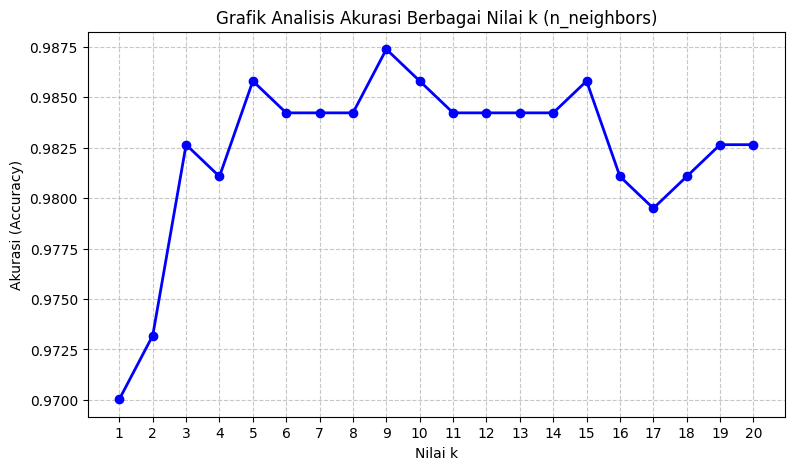


--- Laporan Klasifikasi Akhir ---
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       297
           1       0.99      0.99      0.99       337

    accuracy                           0.99       634
   macro avg       0.99      0.99      0.99       634
weighted avg       0.99      0.99      0.99       634



In [4]:
k_values = range(1, 21)
accuracies = []

for k in k_values:
  knn = KNeighborsClassifier(n_neighbors=k)
  knn.fit(X_train_opt, y_train_opt)
  y_pred_k = knn.predict(X_test_opt)
  accuracies.append(accuracy_score(y_test_opt, y_pred_k))

# Menentukan nilai k terbaik
best_k = k_values[np.argmax(accuracies)]
best_accuracy = max(accuracies)

print(f'\nNilai k terbaik adalah {best_k} dengan akurasi: {best_accuracy:.4f}')

# Plot Grafik Analisis Nilai k
plt.figure(figsize=(9, 5))
plt.plot(
    k_values,
    accuracies,
    marker='o',
    linestyle='-',
    color='b',
    linewidth=2,
    markersize=6,
)
plt.title(
    'Grafik Analisis Akurasi Berbagai Nilai k (n_neighbors)', fontsize=12
)
plt.xlabel('Nilai k', fontsize=10)
plt.ylabel('Akurasi (Accuracy)', fontsize=10)
plt.xticks(k_values)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# Evaluasi akhir dengan k terbaik
final_knn = KNeighborsClassifier(n_neighbors=best_k)
final_knn.fit(X_train_opt, y_train_opt)
final_preds = final_knn.predict(X_test_opt)

print('\n--- Laporan Klasifikasi Akhir ---')
print(classification_report(y_test_opt, final_preds))